# Exploration of Dam Removal Dataset

In [1]:
import pandas as pd

## Initial investigation

In [2]:
dam_df = pd.read_csv('../data/raw/dams/ARDamRemovalList_Figshare_Mar2026.csv')
dam_df.head()

,AR_ID,NABI_ID,NID_ID,Dam_Name,Year_Removed,Latitude,Longitude,City_County,River,HUC8,...,Dam_Length_ft,Year_Built,Owner,Original_Use,Type_Material,Reason_for_removal,Miles_Restored_US,Miles_Restored_DS,River_Miles_Reported,Last_Updated
0,AK-001,AK91779,NaN,Lake Bettinger Complex Dam,NaN,57.80333,-152.395,Kodiak,NaN,Kodiak-Afognak Islands,...,251,1959,City of Kodiak,Water Supply,Timber,Delapidated,NaN,NaN,NaN,2/10/2026
1,AK-002,AK91780,NaN,Bettinger Lower Reservoir Dam B,NaN,57.80167,-152.395,Kodiak,NaN,Kodiak-Afognak Islands,...,245,1959,City of Kodiak,Water Supply,Timber,Safety,NaN,NaN,NaN,2/10/2026
2,AK-003,AK91781,NaN,Memory Estates Dam #1,NaN,62.61833,-149.427,Matanuska-Susitna,NaN,Talkeetna River,...,379,1973,NaN,Recreation,Earthen,NaN,NaN,NaN,NaN,2/10/2026
3,AK-004,AK91782,NaN,Memory Estates Dam #2,NaN,62.62667,-149.380,Matanuska-Susitna,NaN,Talkeetna River,...,444,1973,NaN,Recreation,Earthen,NaN,NaN,NaN,NaN,2/10/2026
4,AK-005,NaN,NaN,Switzer One Dam,1988,NaN,NaN,"Tongass National Forest, Juneau",Switzer Creek,Lynn Canal,...,NaN,NaN,NaN,NaN,NaN,Safety,NaN,NaN,NaN,11/10/2017


In [3]:
dam_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2325 entries, 0 to 2324
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   AR_ID                 2325 non-null   str    
 1   NABI_ID               2122 non-null   str    
 2   NID_ID                537 non-null    str    
 3   Dam_Name              2325 non-null   str    
 4   Year_Removed          2185 non-null   str    
 5   Latitude              2126 non-null   float64
 6   Longitude             2126 non-null   float64
 7   City_County           2167 non-null   str    
 8   River                 2252 non-null   str    
 9   HUC8                  2140 non-null   str    
 10  State                 2325 non-null   str    
 11  Dam_Height_ft         1766 non-null   str    
 12  Dam_Length_ft         1376 non-null   str    
 13  Year_Built            1118 non-null   str    
 14  Owner                 1158 non-null   str    
 15  Original_Use          1198 non-n

In [4]:
dam_df.dtypes

AR_ID                       str
NABI_ID                     str
NID_ID                      str
Dam_Name                    str
Year_Removed                str
Latitude                float64
Longitude               float64
City_County                 str
River                       str
HUC8                        str
State                       str
Dam_Height_ft               str
Dam_Length_ft               str
Year_Built                  str
Owner                       str
Original_Use                str
Type_Material               str
Reason_for_removal          str
Miles_Restored_US           str
Miles_Restored_DS           str
River_Miles_Reported        str
Last_Updated                str
dtype: object

Except for latitude and longitude, all features are object types. In order to get informative descriptive statistics and perform more extensive EDA, some of these features will be converted to numeric data types below.

In [5]:
numeric_cols = [
    "Dam_Height_ft",
    "Dam_Length_ft",
    "Miles_Restored_US",
    "Miles_Restored_DS",
    "River_Miles_Reported"
]

for col in numeric_cols:
    dam_df[col] = pd.to_numeric(dam_df[col], errors="coerce")

dam_df["Year_Removed"] = pd.to_numeric(
    dam_df["Year_Removed"], errors="coerce"
).astype("Int64")

dam_df["Year_Built"] = pd.to_numeric(
    dam_df["Year_Built"], errors="coerce"
).astype("Int64")

dam_df["Last_Updated"] = pd.to_datetime(
    dam_df["Last_Updated"], errors="coerce"
)

text_cols = [
    "AR_ID", "NABI_ID", "NID_ID", "Dam_Name",
    "City_County", "River", "HUC8", "State",
    "Owner", "Original_Use", "Type_Material",
    "Reason_for_removal"
]

dam_df[text_cols] = dam_df[text_cols].astype("string")

In [6]:
dam_df.describe()

,Year_Removed,Latitude,Longitude,Dam_Height_ft,Dam_Length_ft,Year_Built,Miles_Restored_US,Miles_Restored_DS,River_Miles_Reported,Last_Updated
count,2182.0,2126.000000,2126.000000,1730.00000,1355.000000,786.0,453.000000,277.000000,486.000000,2325
mean,2009.992667,40.867210,-88.668649,14.33078,231.809668,1924.189567,33.530221,101.715632,21.774835,2025-06-26 23:40:48
min,1912.0,18.455111,-159.673562,1.00000,2.000000,1708.0,0.000000,0.000000,0.000000,2017-11-10 00:00:00
25%,2005.0,39.766655,-93.897923,5.26250,50.000000,1906.0,1.000000,1.600000,1.100000,2026-02-10 00:00:00
50%,2013.0,41.249593,-82.348913,10.00000,120.000000,1931.0,4.000000,4.000000,4.000000,2026-02-10 00:00:00
75%,2019.0,43.469702,-75.658200,17.00000,260.000000,1957.0,16.000000,16.000000,17.000000,2026-02-10 00:00:00
max,2025.0,65.292800,-66.702972,210.00000,7500.000000,2023.0,2622.000000,7275.000000,1873.000000,2026-03-12 00:00:00
std,14.22186,4.447030,18.227580,15.79745,433.489105,44.306155,152.995813,667.602295,97.207537,NaN


## Potential columns to join on

In [7]:
hucs = dam_df["HUC8"].dropna().unique()
print(f"The dam removal dataset has {len(hucs)} unique HUC8 watersheds")

The dam removal dataset has 678 unique HUC8 watersheds


## Explore miles_restored columns

These columns can potentially help determine the cutoff for how far up/downstream a water quality station can be from a dam removal for it to be considered "relevant". As defined by the dam removal dataset's metadata, miles_restored_us/ds refer to "River miles opened for fish passage up/downstream of the former dam structure as reported by stakeholder" and River_Miles_Reported refers to "River miles opened for fish passage as reported by stakeholder (may include only upstream or upstream plus downstream miles)". While these distances refer to fish passage rather than water quality, they can potentially be used as a proxy for hydrologically relevance.

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

cols = [
    "Miles_Restored_US",
    "Miles_Restored_DS",
    "Dam_Height_ft",
    "Dam_Length_ft",
]

dam_df[cols].describe(include="all")

,Miles_Restored_US,Miles_Restored_DS,Dam_Height_ft,Dam_Length_ft
count,453.000000,277.000000,1730.00000,1355.000000
mean,33.530221,101.715632,14.33078,231.809668
std,152.995813,667.602295,15.79745,433.489105
min,0.000000,0.000000,1.00000,2.000000
25%,1.000000,1.600000,5.26250,50.000000
50%,4.000000,4.000000,10.00000,120.000000
75%,16.000000,16.000000,17.00000,260.000000
max,2622.000000,7275.000000,210.00000,7500.000000


In [10]:
summary = pd.DataFrame({
    "non_missing": dam_df[cols].notna().sum(),
    "missing_pct": dam_df[cols].isna().mean() * 100,
    "median": dam_df[cols].median(),
    "mean": dam_df[cols].mean(),
    "p90": dam_df[cols].quantile(0.90),
    "p95": dam_df[cols].quantile(0.95),
    "max": dam_df[cols].max(),
})

summary.round(2)

,non_missing,missing_pct,median,mean,p90,p95,max
Miles_Restored_US,453,80.52,4.0,33.53,43.0,126.6,2622.0
Miles_Restored_DS,277,88.09,4.0,101.72,57.8,180.4,7275.0
Dam_Height_ft,1730,25.59,10.0,14.33,30.0,39.0,210.0
Dam_Length_ft,1355,41.72,120.0,231.81,476.4,746.5,7500.0


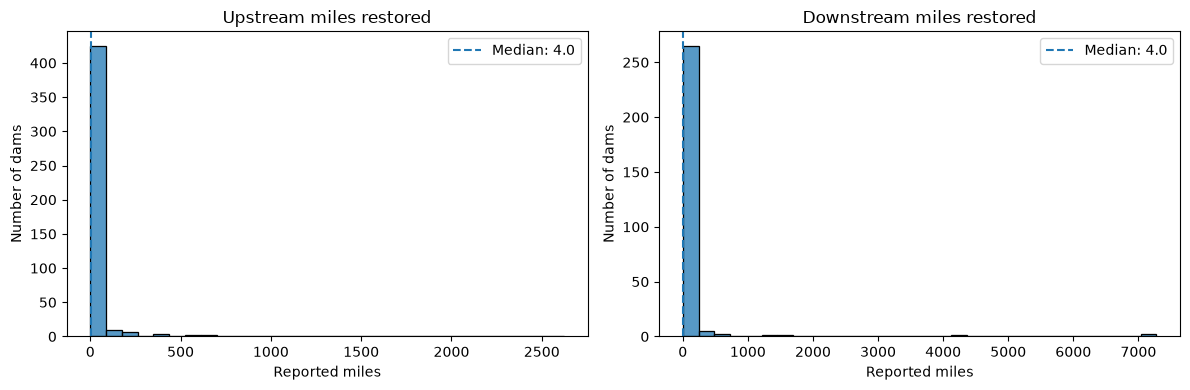

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, col, title in zip(
    axes,
    ["Miles_Restored_US", "Miles_Restored_DS"],
    ["Upstream miles restored", "Downstream miles restored"],
):
    values = dam_df[col].dropna()
    sns.histplot(values, bins=30, ax=ax)
    ax.axvline(values.median(), linestyle="--", label=f"Median: {values.median():.1f}")
    ax.set(title=title, xlabel="Reported miles", ylabel="Number of dams")
    ax.legend()

plt.tight_layout()
plt.show()

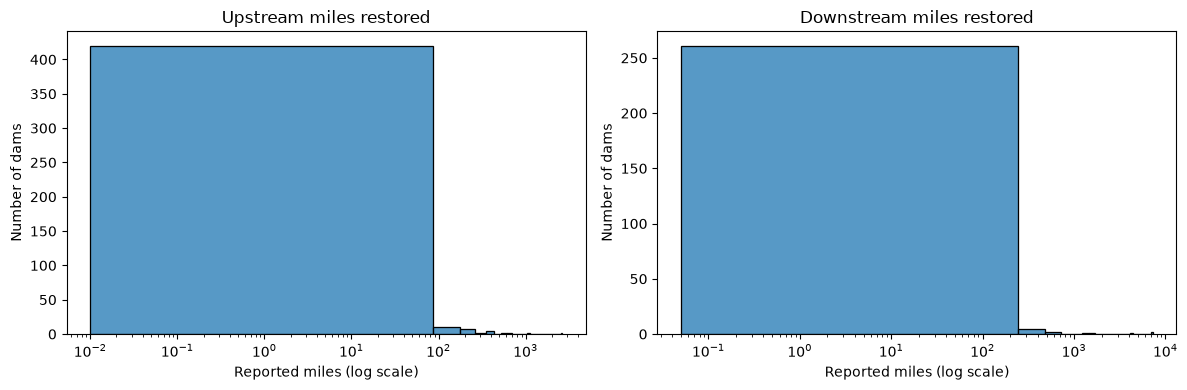

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, col, title in zip(
    axes,
    ["Miles_Restored_US", "Miles_Restored_DS"],
    ["Upstream miles restored", "Downstream miles restored"],
):
    values = dam_df.loc[dam_df[col] > 0, col].dropna()
    sns.histplot(values, bins=30, ax=ax)
    ax.set_xscale("log")
    ax.set(title=title, xlabel="Reported miles (log scale)", ylabel="Number of dams")

plt.tight_layout()
plt.show()

Even after log transforming the data, there is extreme right skew in miles restored. For the purposes of understanding the spread of the majority of the data, we will visualize the spread when we exclude these extreme outliers:

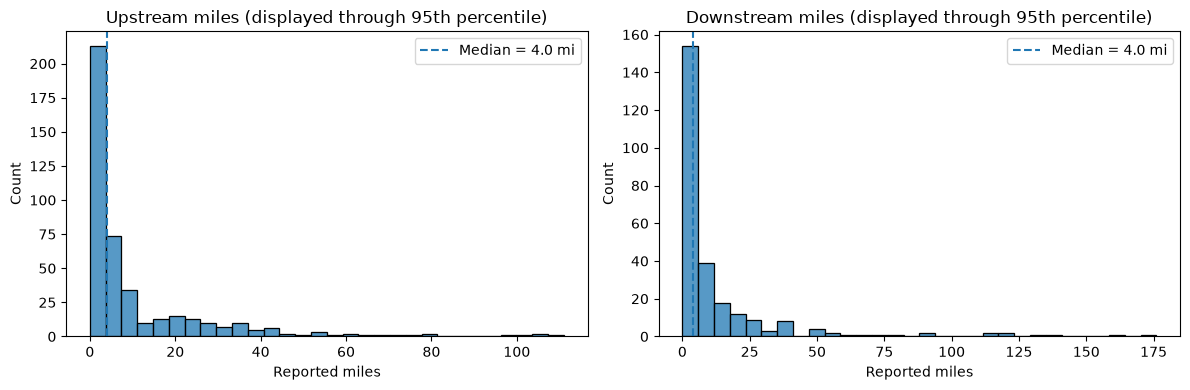

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, col, title in zip(
    axes,
    ["Miles_Restored_US", "Miles_Restored_DS"],
    ["Upstream miles", "Downstream miles"],
):
    values = dam_df[col].dropna()
    upper = values.quantile(0.95)

    sns.histplot(values[values <= upper], bins=30, ax=ax)
    ax.axvline(values.median(), linestyle="--",
               label=f"Median = {values.median():.1f} mi")
    ax.set_title(f"{title} (displayed through 95th percentile)")
    ax.set_xlabel("Reported miles")
    ax.legend()

plt.tight_layout()
plt.show()

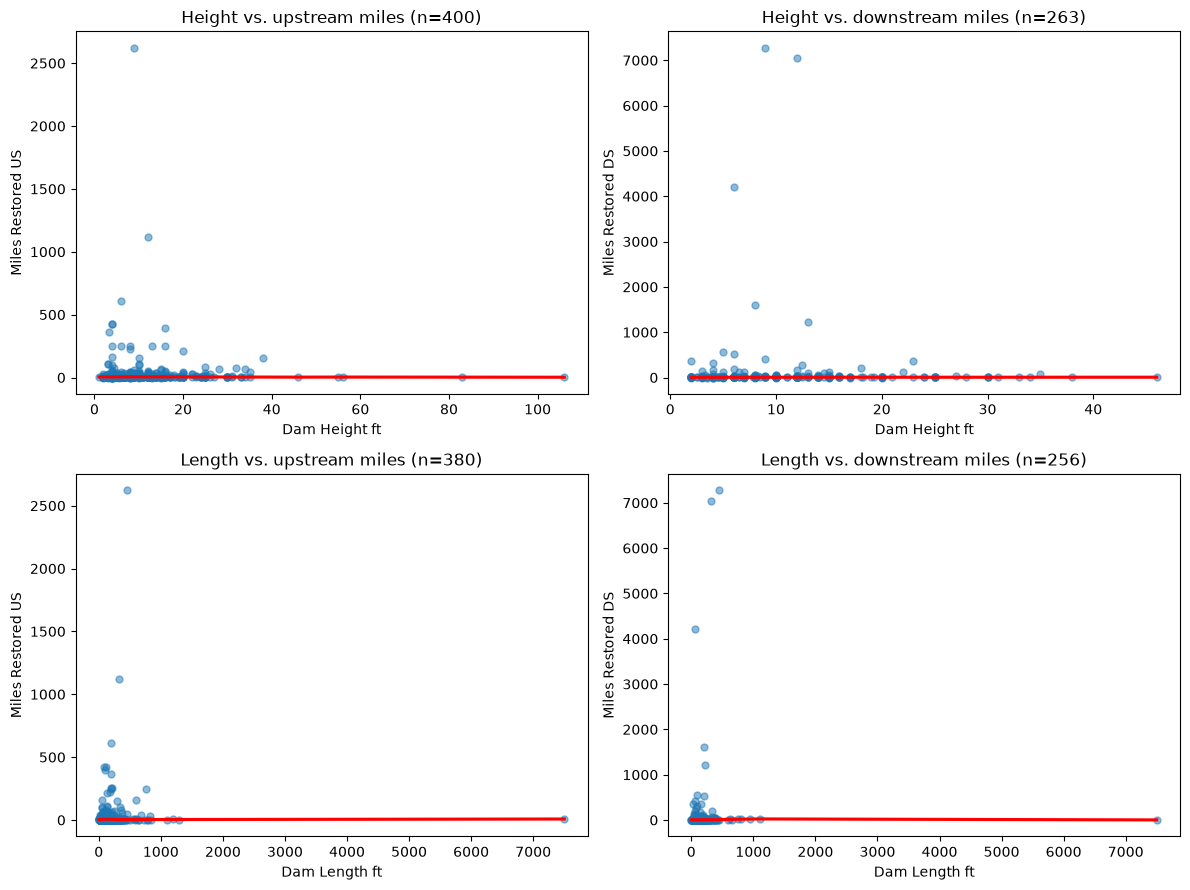

In [13]:
pairs = [
    ("Dam_Height_ft", "Miles_Restored_US", "Height vs. upstream miles"),
    ("Dam_Height_ft", "Miles_Restored_DS", "Height vs. downstream miles"),
    ("Dam_Length_ft", "Miles_Restored_US", "Length vs. upstream miles"),
    ("Dam_Length_ft", "Miles_Restored_DS", "Length vs. downstream miles"),
]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, (x, y, title) in zip(axes.flat, pairs):
    plot_df = dam_df[[x, y]].dropna()

    sns.regplot(
        data=plot_df,
        x=x,
        y=y,
        lowess=True,
        ci=None,
        scatter_kws={"alpha": 0.5, "s": 25},
        line_kws={"color": "red"},
        ax=ax,
    )

    ax.set_title(f"{title} (n={len(plot_df):,})")
    ax.set_xlabel(x.replace("_", " "))
    ax.set_ylabel(y.replace("_", " "))

plt.tight_layout()
plt.show()

In [14]:
from scipy.stats import spearmanr

results = []

for x, y, _ in pairs:
    subset = dam_df[[x, y]].dropna()

    if len(subset) >= 3:
        rho, p_value = spearmanr(subset[x], subset[y])
    else:
        rho, p_value = np.nan, np.nan

    results.append({
        "dam_size_variable": x,
        "restored_miles_variable": y,
        "n": len(subset),
        "spearman_rho": rho,
        "p_value": p_value,
    })

pd.DataFrame(results).round(4)

,dam_size_variable,restored_miles_variable,n,spearman_rho,p_value
0,Dam_Height_ft,Miles_Restored_US,400,0.0272,0.5878
1,Dam_Height_ft,Miles_Restored_DS,263,0.0377,0.5431
2,Dam_Length_ft,Miles_Restored_US,380,0.0936,0.0685
3,Dam_Length_ft,Miles_Restored_DS,256,0.1199,0.0553


Dams with both values: 270


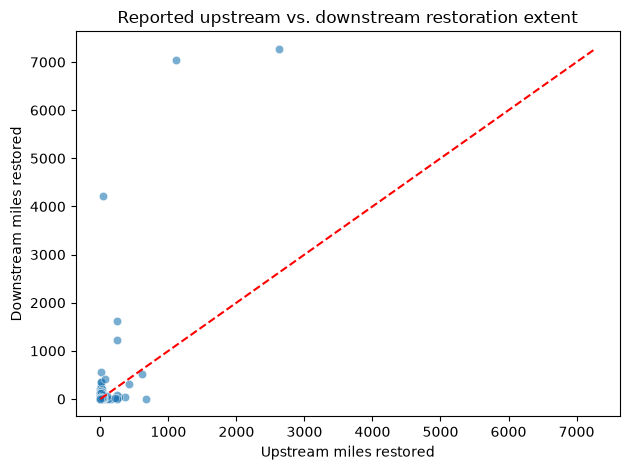

,Miles_Restored_US,Miles_Restored_DS
Miles_Restored_US,1.000000,0.454484
Miles_Restored_DS,0.454484,1.000000


In [15]:
subset = dam_df[
    ["Miles_Restored_US", "Miles_Restored_DS"]
].dropna()

print(f"Dams with both values: {len(subset):,}")

sns.scatterplot(
    data=subset,
    x="Miles_Restored_US",
    y="Miles_Restored_DS",
    alpha=0.6,
)

max_val = subset.max().max()
plt.plot([0, max_val], [0, max_val], linestyle="--", color="red")
plt.xlabel("Upstream miles restored")
plt.ylabel("Downstream miles restored")
plt.title("Reported upstream vs. downstream restoration extent")
plt.tight_layout()
plt.show()

subset.corr(method="spearman")

In [16]:
for col in ["Miles_Restored_US", "Miles_Restored_DS"]:
    print(f"\nLargest values: {col}")

    display(
        dam_df.nlargest(10, col)[
            [
                "AR_ID",
                "Dam_Name",
                "River",
                "State",
                "Year_Removed",
                "Dam_Height_ft",
                "Dam_Length_ft",
                col,
            ]
        ]
    )


Largest values: Miles_Restored_US


,AR_ID,Dam_Name,River,State,Year_Removed,Dam_Height_ft,Dam_Length_ft,Miles_Restored_US
508,IN-027,Rockford Dam (Seymour Water Company Dam),East Fork White River,IN,2024,9.0,450.0,2622.0
1912,TN-038,Harms Mill Dam,Elk River,TN,2025,12.0,325.0,1118.0
510,IN-029,Flatrock River Dam Upper (Geneva Dam- Upper),Flatrock River,IN,2025,NaN,NaN,667.0
533,KY-013,Pineville Dam,Cumberland River,KY,2025,NaN,NaN,626.0
497,IN-016,Sugar Creek Dam (Crawfordsville Power Plant Dam),Sugar Creek,IN,2021,6.0,200.0,611.0
504,IN-023,Corydon North Bridge Dam (Gupta Dam),Big Indian Creek,IN,2024,NaN,NaN,570.0
505,IN-024,Huntington Dam,Little River,IN,2024,4.0,120.0,423.0
335,FL-025,Downs' Dam (Myakka River Dam),Myakka River,FL,2025,4.0,90.0,422.0
16,AL-007,Howle and Turner Dam,Tallapoosa River,AL,2019,16.0,100.0,397.0
334,FL-024,Upper Myakka Lake Dam (Civilian Conservation C...,Myakka River,FL,2022,3.3,200.0,364.0



Largest values: Miles_Restored_DS


,AR_ID,Dam_Name,River,State,Year_Removed,Dam_Height_ft,Dam_Length_ft,Miles_Restored_DS
508,IN-027,Rockford Dam (Seymour Water Company Dam),East Fork White River,IN,2024,9.0,450.0,7275.0
1912,TN-038,Harms Mill Dam,Elk River,TN,2025,12.0,325.0,7048.0
1992,VA-055,Baber's Mill Dam,Rock Island Creek,VA,2024,6.0,55.0,4208.0
1832,PA-433,Bedford Dam No. 1,Raystown Branch Juniata River,PA,2025,8.0,200.0,1610.0
1991,VA-054,Ashland Mill Dam,South Anna River,VA,2024,13.0,220.0,1221.0
1737,PA-338,Krady Mill Dam,Chiques Creek,PA,2018,5.0,100.0,554.0
497,IN-016,Sugar Creek Dam (Crawfordsville Power Plant Dam),Sugar Creek,IN,2021,6.0,200.0,521.0
1914,TN-040,Pistol Creek Dam (Alcoa Dam),Pistol Creek,TN,2025,9.0,62.0,410.0
838,MI-122,Hulbert Road Dam,Au Sable River,MI,2025,2.0,35.0,360.0
834,MI-118,Lower Dam,East Branch Ontonagon River,MI,2024,23.0,160.0,354.0


### Display all dam removals with both miles_restored_us and miles_restored_ds

In [28]:
import pandas as pd
import folium
from folium.plugins import MarkerCluster

subset = dam_df.dropna(
    subset=[
        "Latitude",
        "Longitude",
        "Miles_Restored_US",
        "Miles_Restored_DS",
    ]
).copy()

print(f"Total dams: {len(dam_df):,}")
print(f"Dams in subset: {len(subset):,}")

Total dams: 2,325
Dams in subset: 268


In [29]:
center = [
    subset["Latitude"].median(),
    subset["Longitude"].median(),
]

m = folium.Map(
    location=center,
    zoom_start=5,
    tiles="OpenStreetMap",
)

for _, row in subset.iterrows():
    popup_html = f"""
    <b>{row.get('Dam_Name', 'Unknown dam')}</b><br>
    State: {row.get('State', 'Unknown')}<br>
    River: {row.get('River', 'Unknown')}<br>
    Year removed: {row.get('Year_Removed', 'Unknown')}<br>
    Upstream miles restored: {row['Miles_Restored_US']}<br>
    Downstream miles restored: {row['Miles_Restored_DS']}
    """

    folium.CircleMarker(
        location=[row["Latitude"], row["Longitude"]],
        radius=4,
        color="red",
        fill=True,
        fill_opacity=0.7,
        tooltip=str(row.get("Dam_Name", "Unknown dam")),
        popup=folium.Popup(popup_html, max_width=300),
    ).add_to(m)

m